# M7 · G_eff law over 25 generator subsets

**M6 result** (mean held-out video AUC %): pooled 87.49 · **GBLA 88.04** · Fisher 85.34 · uniform 81.06.

GBLA beats a post-hoc Fisher merge of the same specialists by **+2.7** points. Fisher itself is worse than joint pooled training (−2.2). So private offsets during training help in a way that merging finished models does not. The gain is concentrated on Face2Face and FaceShifter; NeuralTextures as held-out still favours pooling.

**M7.** The remaining planned measurement: how generator dominance (geometric G_eff) and OOD accuracy change across subsets of the five FF++ manipulations. The 25 subsets are all of size 2, 3 and 4:

| size | count | reused from |
|---|---|---|
| 4 | 5 | M5 λ = ∞ (4 folds) + M4 λ = ∞ (FaceShifter fold) |
| 3 | 10 | new pooled runs |
| 2 | 10 | new pooled runs |

For every subset S:

1. **Pooled solution θ\*_S** — LN tuning on generators in S only (same recipe as M4 λ = ∞: one generator per block, 1/|S| of the reals each, 10 epochs). Each generator keeps all its fakes; smaller subsets therefore get more reals per generator and slightly longer epochs.
2. **Geometric G_eff** — write θ\*_S − θ0 ≈ Σ_{g∈S} w_g (v_g − θ0) in the span of the single-generator solutions (M3 + M6). G_eff = (Σw)² / Σw² (Kish). G_eff / |S| = 1 means equal pull.
3. **OOD video AUC** — mean over generators not in S (and each one listed).

The law we look for: whether lower G_eff / |S| (more dominance) predicts worse OOD, and how G_eff scales with subset size and composition.

| Section | What it does | Run time |
|---|---|---|
| 1–3 | settings, data, detector, load all 5 v_g | ~3 min |
| 4.1 | pooled training for size 2 and 3 (resumable); size 4 from M5 | ~20–26 h |
| 4.2 | geometric G_eff for every subset | ~5 min |
| 5 | G_eff vs size, G_eff vs OOD, tables | minutes |

## 1. Setup

### 1.1 Settings

In [1]:
# 1.1 Settings
import os
from pathlib import Path
from itertools import combinations

DATA_ROOT = Path("/nlsasfs/home/isea/isea64/GBLA-Deepfake Detection")
FACES_ROOT = DATA_ROOT / "faces"
INDEX_CSV = DATA_ROOT / "index" / "ffpp_c23.csv"
RUNS_ROOT = DATA_ROOT / "runs"
M7_DIR = RUNS_ROOT / "m7"
M3_DIR = RUNS_ROOT / "m3"
M4_DIR = RUNS_ROOT / "m4"
M5_DIR = RUNS_ROOT / "m5"
M6_DIR = RUNS_ROOT / "m6"

ALL_GENERATORS = ["Deepfakes", "Face2Face", "FaceSwap", "NeuralTextures", "FaceShifter"]
SHORT = {"original": "real", "Deepfakes": "DF", "Face2Face": "F2F", "FaceSwap": "FS",
         "NeuralTextures": "NT", "FaceShifter": "FSh"}

ARCH, PRETRAINED = "ViT-L-14", "openai"
L2_NORM = True
W_UNIFORM, W_ALIGN = 0.5, 0.1
AUGMENT = True
BATCH_SIZE = 128
EPOCHS = 10
CYCLE_EPOCHS = 10
WARMUP_EPOCHS = 1
LR_MAX, LR_MIN = 3e-4, 1e-5
SEED = 0
SUBSETS = [tuple(s) for k in (4, 3, 2) for s in combinations(ALL_GENERATORS, k)]
assert len(SUBSETS) == 25

VAL_FRAMES_PER_VIDEO = 8
CACHE_IN_RAM = True
EVAL_BATCH = 256
GRAD_CHECKPOINTING = False

assert INDEX_CSV.exists()
M7_DIR.mkdir(parents=True, exist_ok=True)
print("M7 runs go to:", M7_DIR)
print("subsets:", len(SUBSETS), "  sizes:", {k: sum(1 for s in SUBSETS if len(s) == k) for k in (2, 3, 4)})

M7 runs go to: /nlsasfs/home/isea/isea64/GBLA-Deepfake Detection/runs/m7
subsets: 25   sizes: {2: 10, 3: 10, 4: 5}


### 1.2 Imports and environment

In [2]:
# 1.2 Imports and environment
import json, math, time
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor

import matplotlib.pyplot as plt
import numpy as np
import open_clip
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from torch.utils.data import DataLoader, Dataset, Sampler
from torchvision import tv_tensors
from torchvision.io import ImageReadMode, read_image
from torchvision.transforms import v2 as T
from tqdm.auto import tqdm

torch.manual_seed(SEED)
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True
assert torch.cuda.is_available(), "M7 needs the GPU"
DEVICE = "cuda"


def usable_cpus():
    n = len(os.sched_getaffinity(0))
    for quota_file, period_file in [("/sys/fs/cgroup/cpu.max", None),
                                    ("/sys/fs/cgroup/cpu/cpu.cfs_quota_us", "/sys/fs/cgroup/cpu/cpu.cfs_period_us")]:
        try:
            if period_file is None:
                quota, period = Path(quota_file).read_text().split()
            else:
                quota, period = Path(quota_file).read_text().strip(), Path(period_file).read_text().strip()
            if quota not in ("max", "-1"):
                n = min(n, max(1, int(quota) // int(period)))
        except (OSError, ValueError):
            pass
    return n


def available_memory_gb():
    try:
        meminfo = dict(line.split(":", 1) for line in Path("/proc/meminfo").read_text().splitlines())
        return int(meminfo["MemAvailable"].split()[0]) * 1024 / 1e9
    except (OSError, KeyError, ValueError):
        return 0.0


CPUS = usable_cpus()
NUM_WORKERS = max(1, min(16, CPUS - 1))
torch.set_num_threads(2)
pd.Series({
    "torch": torch.__version__, "GPU": torch.cuda.get_device_name(0),
    "CPUs": CPUS, "workers": NUM_WORKERS, "free RAM (GB)": round(available_memory_gb(), 1),
}, name="value").to_frame()

/nlsasfs/home/isea/isea64/venv_jupyter/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,value
torch,2.6.0+cu124
GPU,NVIDIA A100-SXM4-40GB
CPUs,8
workers,7
free RAM (GB),1050.0


## 2. Data

In [3]:
# 2.1 Index and crops
index = pd.read_csv(INDEX_CSV, dtype={"video_id": str, "target_id": str, "source_id": str},
                    keep_default_na=False)
CATEGORIES = ["original"] + ALL_GENERATORS
GEN_CODE = {g: k for k, g in enumerate(CATEGORIES)}


def subset(split, generators):
    keep = (index.split == split) & index.generator.isin(["original", *generators])
    return index[keep].reset_index(drop=True)


full_train = subset("train", ALL_GENERATORS)
test_df = subset("test", ALL_GENERATORS)


def load_images(df, desc):
    paths = [FACES_ROOT / p for p in df.path]
    first = np.asarray(Image.open(paths[0]).convert("RGB"))
    out = np.empty((len(paths), *first.shape), dtype=np.uint8)

    def work(k):
        out[k] = np.asarray(Image.open(paths[k]).convert("RGB"))

    with ThreadPoolExecutor(max_workers=min(32, 4 * CPUS)) as pool:
        list(tqdm(pool.map(work, range(len(paths))), total=len(paths), desc=desc, mininterval=5))
    return out


images = {}
budget = 0.6 * available_memory_gb()
for name, df in [("train", full_train), ("test", test_df)]:
    need = len(df) * 224 * 224 * 3 / 1e9
    if CACHE_IN_RAM and need <= budget:
        t = time.time()
        images[name] = load_images(df, f"{name} -> RAM")
        budget -= need
        print(f"{name}: {len(df):,} crops, {need:.1f} GB, {(time.time() - t) / 60:.1f} min")
    else:
        images[name] = None
        print(f"{name}: from disk")

train -> RAM: 100%|██████████| 138240/138240 [01:21<00:00, 1692.43it/s]


train: 138,240 crops, 20.8 GB, 1.4 min


test -> RAM: 100%|██████████| 26880/26880 [00:15<00:00, 1681.08it/s]

test: 26,880 crops, 4.0 GB, 0.3 min


In [4]:
# 2.2 Dataset and subset sampler
CLIP_MEAN = (0.48145466, 0.4578275, 0.40821073)
CLIP_STD = (0.26862954, 0.26130258, 0.27577711)


def make_transform(train):
    steps = []
    if train and AUGMENT:
        steps += [
            T.RandomHorizontalFlip(0.5),
            T.RandomAffine(degrees=10, translate=(0.1, 0.1), scale=(0.9, 1.1)),
            T.RandomApply([T.GaussianBlur(kernel_size=7, sigma=(0.1, 2.0))], p=0.1),
            T.ColorJitter(brightness=0.1, contrast=0.1),
            T.JPEG(quality=(40, 100)),
        ]
    steps += [T.ToDtype(torch.float32, scale=True), T.Normalize(CLIP_MEAN, CLIP_STD)]
    return T.Compose(steps)


class FaceDataset(Dataset):
    def __init__(self, df, train, imgs=None):
        self.paths = [str(FACES_ROOT / p) for p in df.path]
        self.images = imgs
        self.labels = torch.tensor(df.label.values, dtype=torch.long)
        self.gens = torch.tensor(df.generator.map(GEN_CODE).values, dtype=torch.long)
        self.transform = make_transform(train)

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        if self.images is not None:
            image = torch.from_numpy(np.array(self.images[i])).permute(2, 0, 1)
        else:
            image = read_image(self.paths[i], mode=ImageReadMode.RGB)
        return self.transform(tv_tensors.Image(image)).as_subclass(torch.Tensor), self.labels[i], self.gens[i]


class SubsetSampler(Sampler):
    """One epoch = one block per generator in S. Block = all fakes + 1/|S| of reals (fixed split)."""

    def __init__(self, df, seed):
        self.df_gen = df.generator.values
        self.real_idx = np.flatnonzero(self.df_gen == "original")
        self.seed = seed
        self.epoch = 0
        self.gens = []
        self.blocks = {}
        self.n = 0

    def set_subset(self, gens):
        self.gens = list(gens)
        gcount = len(self.gens)
        self.blocks = {}
        for k, g in enumerate(self.gens):
            fakes = np.flatnonzero(self.df_gen == g)
            reals = self.real_idx[k::gcount][: len(fakes) // gcount]
            self.blocks[g] = (fakes, reals)
        self.n = sum(len(a) + len(b) for a, b in self.blocks.values())

    def set_epoch(self, epoch):
        self.epoch = epoch

    def __iter__(self):
        order = np.random.default_rng([self.seed, self.epoch, 1])
        gens = list(self.gens)
        order.shuffle(gens)
        out = []
        for g in gens:
            fakes, reals = self.blocks[g]
            rng = np.random.default_rng([self.seed, ALL_GENERATORS.index(g), self.epoch])
            out.extend(rng.permutation(np.concatenate([fakes, reals])).tolist())
        return iter(out)

    def __len__(self):
        return self.n


train_ds = FaceDataset(full_train, train=True, imgs=images["train"])
train_sampler = SubsetSampler(full_train, SEED)
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, sampler=train_sampler, drop_last=True,
                          num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=NUM_WORKERS > 0,
                          prefetch_factor=4 if NUM_WORKERS else None)
print("loader ready")

loader ready


## 3. Model

In [5]:
# 3.1 Detector
class Detector(nn.Module):
    def __init__(self):
        super().__init__()
        encoder = open_clip.create_model(ARCH, pretrained=PRETRAINED, force_quick_gelu=True).visual
        encoder.proj = None
        self.encoder = encoder
        self.head = nn.Linear(encoder.transformer.width, 2)

    def forward(self, x):
        feats = self.encoder(x).float()
        f = F.normalize(feats, dim=-1)
        return self.head(f if L2_NORM else feats), f


torch.manual_seed(SEED)
model = Detector().to(DEVICE)
model.requires_grad_(False)
for m in model.encoder.modules():
    if isinstance(m, nn.LayerNorm):
        m.requires_grad_(True)
model.head.requires_grad_(True)
model.encoder.set_grad_checkpointing(GRAD_CHECKPOINTING)

PARAMS = [(n, p) for n, p in model.named_parameters() if p.requires_grad]
PARAM_NAMES = [n for n, _ in PARAMS]
P = sum(p.numel() for _, p in PARAMS)


def get_flat():
    return torch.cat([p.detach().reshape(-1) for _, p in PARAMS]).float()


@torch.no_grad()
def set_flat(theta):
    offset = 0
    for _, p in PARAMS:
        n = p.numel()
        p.copy_(theta[offset:offset + n].view_as(p))
        offset += n


def flat_from_state(state):
    return torch.cat([state[n].reshape(-1).float() for n in PARAM_NAMES]).to(DEVICE)


def trainable_state():
    return {n: p.detach().cpu().clone() for n, p in PARAMS}


THETA0 = get_flat().clone()
print(f"P = {P:,}")
assert P == 104_450

P = 104,450


## 4. Pooled solutions and G_eff

### 4.1 Train pooled models on each subset (resumable)

Size-4 subsets reuse M5 λ = ∞ for NT/FS/DF/F2F and M4 λ = ∞ for FaceShifter (M5 never retrained that fold). Size 2 and 3 are trained here under `runs/m7/pool_<tag>_.../`. Tag = generators joined by `+` (e.g. `DF+FS`). Kernel → Interrupt is safe; finished subsets are skipped.

In [6]:
# 4.1 Helpers + pooled training
MEAN_GPU = torch.tensor(CLIP_MEAN, device=DEVICE).view(1, 3, 1, 1)
STD_GPU = torch.tensor(CLIP_STD, device=DEVICE).view(1, 3, 1, 1)


def compute_loss(logits, f, y):
    ce_each = F.cross_entropy(logits, y, reduction="none")
    ce = ce_each.mean()
    n = len(y)
    i, j = torch.triu_indices(n, n, offset=1, device=f.device)
    d2 = (2 - 2 * (f @ f.T)[i, j]).clamp(min=0)
    same = y[i] == y[j]
    align = d2[same].mean() if same.any() else d2.new_zeros(())
    uniform = torch.exp(-2 * d2).mean().clamp(min=1e-6).log()
    loss = ce + W_ALIGN * align + W_UNIFORM * uniform
    return loss, {"loss": loss.item(), "ce": ce.item()}


def lr_at(step, steps_per_epoch):
    cycle = CYCLE_EPOCHS * steps_per_epoch
    warm = WARMUP_EPOCHS * steps_per_epoch
    pos = step % cycle
    if pos < warm:
        return LR_MIN + (LR_MAX - LR_MIN) * pos / warm
    frac = (pos - warm) / max(cycle - warm, 1)
    return LR_MIN + 0.5 * (LR_MAX - LR_MIN) * (1 + math.cos(math.pi * frac))


def save_atomic(obj, path):
    tmp = path.with_name(path.name + ".tmp")
    torch.save(obj, tmp)
    os.replace(tmp, path)


def load(path):
    return torch.load(path, map_location="cpu", weights_only=False)


def subset_tag(gens):
    return "+".join(SHORT[g] for g in gens)


def run_dir_for(gens):
    return M7_DIR / f"pool_{subset_tag(gens)}_{ARCH}_seed{SEED}"


def size4_pool_dir(gens):
    """Size-4 subset S <=> hold out the one generator not in S.

    M5 wrote logo_hold-* for NT/FS/DF/F2F. The FaceShifter fold was never
    retrained: M5 reused M4's gbla_laminf_* run.
    """
    held = [g for g in ALL_GENERATORS if g not in gens]
    assert len(held) == 1
    h = held[0]
    if h == "FaceShifter":
        return M4_DIR / f"gbla_laminf_{ARCH}_seed{SEED}"
    return M5_DIR / f"logo_hold-{SHORT[h]}_laminf_{ARCH}_seed{SEED}"


def single_gen_path(g):
    if g == "FaceShifter":
        return M6_DIR / f"lnclip_{ARCH}_train-{SHORT[g]}_seed{SEED}" / f"epoch_{EPOCHS:02d}.pt"
    return M3_DIR / f"lnclip_{ARCH}_train-{SHORT[g]}_seed{SEED}" / f"epoch_{EPOCHS:02d}.pt"


def load_pooled_theta(gens):
    """Return flat theta* for subset gens, from M4/M5 (size 4) or M7 (size 2/3)."""
    if len(gens) == 4:
        path = size4_pool_dir(gens) / "last.pt"
        ckpt = load(path)
        return ckpt["gbla"]["theta_s"].to(DEVICE).float()
    path = run_dir_for(gens) / f"epoch_{EPOCHS:02d}.pt"
    return flat_from_state(load(path))


def train_pooled(gens):
    gens = list(gens)
    if len(gens) == 4:
        path = size4_pool_dir(gens) / "last.pt"
        assert path.exists(), f"missing size-4 pooled run: {path}"
        src = "M4" if "m4" in str(path) else "M5"
        print(f"size 4 {{{subset_tag(gens)}}}: reuse {src}")
        return
    run_dir = run_dir_for(gens)
    run_dir.mkdir(parents=True, exist_ok=True)
    cfg = {"gens": gens, "epochs": EPOCHS, "seed": SEED, "arch": ARCH,
           "reals_per_gen": f"1/{len(gens)} of train reals (fixed split)"}
    cfg_path = run_dir / "config.json"
    if cfg_path.exists():
        assert json.loads(cfg_path.read_text()) == cfg
    else:
        cfg_path.write_text(json.dumps(cfg, indent=1))
    set_flat(THETA0)
    opt = torch.optim.AdamW([p for _, p in PARAMS], lr=LR_MIN, betas=(0.9, 0.999), weight_decay=0.0)
    history, start = [], 0
    if (run_dir / "last.pt").exists():
        ckpt = load(run_dir / "last.pt")
        set_flat(flat_from_state(ckpt["trainable"]))
        opt.load_state_dict(ckpt["optimizer"])
        history, start = ckpt["history"], ckpt["epoch"]
    print(f"\n===== pool {{{subset_tag(gens)}}}: {start}/{EPOCHS} =====")
    if start >= EPOCHS and (run_dir / f"epoch_{EPOCHS:02d}.pt").exists():
        print("already done")
        return
    train_sampler.set_subset(gens)
    steps = len(train_loader)
    # |S|=4 -> 225 steps/gen; |S|=3 -> 240; |S|=2 -> 270 (more reals per gen as |S| shrinks)
    print(f"steps/epoch={steps} ({steps // len(gens)} per generator)")
    for epoch in range(start, EPOCHS):
        train_sampler.set_epoch(epoch)
        model.train()
        sums, n, t0 = defaultdict(float), 0, time.time()
        for i, (x, y, gen) in enumerate(tqdm(train_loader, desc=f"{subset_tag(gens)} ep {epoch + 1}", leave=False)):
            lr = lr_at(epoch * steps + i, steps)
            for group in opt.param_groups:
                group["lr"] = lr
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            with torch.autocast("cuda", dtype=torch.bfloat16):
                logits, f = model(x)
            loss, parts = compute_loss(logits.float(), f.float(), y)
            opt.zero_grad(set_to_none=True)
            loss.backward()
            opt.step()
            for k, v in parts.items():
                sums[k] += v
            n += 1
        row = {"epoch": epoch + 1, **{k: v / n for k, v in sums.items()}, "minutes": (time.time() - t0) / 60}
        history.append(row)
        save_atomic(trainable_state(), run_dir / f"epoch_{epoch + 1:02d}.pt")
        save_atomic({"epoch": epoch + 1, "trainable": trainable_state(), "optimizer": opt.state_dict(),
                     "history": history}, run_dir / "last.pt")
        print(" | ".join(f"{k} {v:.4g}" if isinstance(v, float) else f"{k} {v}" for k, v in row.items()))
    del opt
    torch.cuda.empty_cache()


for gens in SUBSETS:
    train_pooled(gens)
print("all pooled solutions ready")

size 4 {DF+F2F+FS+NT}: reuse M4
size 4 {DF+F2F+FS+FSh}: reuse M5
size 4 {DF+F2F+NT+FSh}: reuse M5
size 4 {DF+FS+NT+FSh}: reuse M5
size 4 {F2F+FS+NT+FSh}: reuse M5

===== pool {DF+F2F+FS}: 10/10 =====
already done

===== pool {DF+F2F+NT}: 10/10 =====
already done

===== pool {DF+F2F+FSh}: 10/10 =====
already done

===== pool {DF+FS+NT}: 10/10 =====
already done

===== pool {DF+FS+FSh}: 10/10 =====
already done

===== pool {DF+NT+FSh}: 10/10 =====
already done

===== pool {F2F+FS+NT}: 10/10 =====
already done

===== pool {F2F+FS+FSh}: 10/10 =====
already done

===== pool {F2F+NT+FSh}: 10/10 =====
already done

===== pool {FS+NT+FSh}: 10/10 =====
already done

===== pool {DF+F2F}: 10/10 =====
already done

===== pool {DF+FS}: 10/10 =====
already done

===== pool {DF+NT}: 10/10 =====
already done

===== pool {DF+FSh}: 10/10 =====
already done

===== pool {F2F+FS}: 10/10 =====
already done

===== pool {F2F+NT}: 10/10 =====
already done

===== pool {F2F+FSh}: 10/10 =====
already done

===== 

### 4.2 Geometric G_eff and OOD AUC

Load all five single-generator solutions v_g. For each subset S, project θ\*_S − θ0 onto the span of {v_g − θ0 : g ∈ S}, solve for weights w, and compute G_eff. Then score θ\*_S on every generator not in S.

In [7]:
# 4.2 Geometric G_eff and OOD
def to_model_input(uint8_batch):
    x = torch.as_tensor(uint8_batch).to(DEVICE, non_blocking=True)
    return (x.permute(0, 3, 1, 2).float() / 255 - MEAN_GPU) / STD_GPU


@torch.no_grad()
def predict(theta, df, imgs=None, desc="predict"):
    set_flat(theta.detach())
    model.eval()
    probs = []
    if imgs is not None:
        for s in tqdm(range(0, len(df), EVAL_BATCH), desc=desc, leave=False):
            with torch.autocast("cuda", dtype=torch.bfloat16):
                logits, _ = model(to_model_input(imgs[s:s + EVAL_BATCH]))
            probs.append(logits.float().softmax(1)[:, 1].cpu())
    else:
        loader = DataLoader(FaceDataset(df, train=False), batch_size=EVAL_BATCH, shuffle=False,
                            num_workers=NUM_WORKERS, pin_memory=True)
        for x, _, _ in tqdm(loader, desc=desc, leave=False):
            with torch.autocast("cuda", dtype=torch.bfloat16):
                logits, _ = model(x.to(DEVICE, non_blocking=True))
            probs.append(logits.float().softmax(1)[:, 1].cpu())
    model.train()
    out = df[["label", "generator", "video_id"]].copy()
    out["prob"] = torch.cat(probs).numpy()
    return out


def auc(labels, scores):
    labels = np.asarray(labels)
    ranks = pd.Series(np.asarray(scores)).rank().values
    n_pos, n_neg = labels.sum(), len(labels) - labels.sum()
    if n_pos == 0 or n_neg == 0:
        return float("nan")
    return float((ranks[labels == 1].sum() - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg))


def video_auc(pred, gens):
    sub = pred[pred.generator.isin(["original", *gens])]
    if (sub.label == 1).sum() == 0:
        return float("nan")
    vid = sub.groupby(["generator", "video_id"], as_index=False).agg(label=("label", "first"), prob=("prob", "mean"))
    return 100 * auc(vid.label, vid.prob)


def g_eff(w):
    w = np.asarray(w, dtype=float)
    return float(w.sum() ** 2 / (w ** 2).sum())


V = {g: flat_from_state(load(single_gen_path(g))) for g in ALL_GENERATORS}
for g in ALL_GENERATORS:
    print(f"{SHORT[g]}: ||v-theta0|| = {(V[g] - THETA0).norm():.2f}")

law_path = M7_DIR / "geff_law.json"
if law_path.exists():
    rows = json.loads(law_path.read_text())
else:
    rows = []
    for gens in tqdm(SUBSETS, desc="subsets"):
        gens = list(gens)
        tag = subset_tag(gens)
        theta_star = load_pooled_theta(gens)
        D = torch.stack([V[g] - THETA0 for g in gens], 1).double()          # P x |S|
        d_star = (theta_star - THETA0).double()
        U, _ = torch.linalg.qr(D)
        C = (U.T @ D).cpu().numpy()
        c_star = (U.T @ d_star).cpu().numpy()
        explained = float(np.linalg.norm(c_star) ** 2 / max(d_star.norm().item() ** 2, 1e-12))
        w = np.linalg.solve(C, c_star)
        w_norm = w / w.sum() if abs(w.sum()) > 1e-12 else w
        ood = [g for g in ALL_GENERATORS if g not in gens]
        pred = predict(theta_star, test_df, images["test"], desc=tag)
        ood_each = {SHORT[g]: video_auc(pred, [g]) for g in ood}
        seen_auc = video_auc(pred, gens)
        row = {
            "subset": tag,
            "size": len(gens),
            "G_eff": g_eff(w_norm),
            "G_eff/|S|": g_eff(w_norm) / len(gens),
            "explained": explained,
            "seen AUC": seen_auc,
            "OOD mean AUC": float(np.mean(list(ood_each.values()))),
            "weights": {SHORT[g]: float(w_norm[i]) for i, g in enumerate(gens)},
            "OOD each": ood_each,
            "sum_w_raw": float(w.sum()),
        }
        rows.append(row)
        print(f"{tag}: G_eff={row['G_eff']:.2f}  G_eff/|S|={row['G_eff/|S|']:.3f}  "
              f"explained={explained:.3f}  OOD={row['OOD mean AUC']:.2f}  seen={seen_auc:.2f}")
    law_path.write_text(json.dumps(rows, indent=1))
print("subsets measured:", len(rows))

DF: ||v-theta0|| = 18.24
F2F: ||v-theta0|| = 18.11
FS: ||v-theta0|| = 18.28
NT: ||v-theta0|| = 15.01
FSh: ||v-theta0|| = 18.72
subsets measured: 25


## 5. The G_eff law

Left: G_eff / |S| by subset size (1 = equal weights). Middle: OOD mean AUC vs G_eff / |S| (each point one subset). Right: OOD mean AUC by subset size. Tables: full numbers, and the subsets with lowest / highest dominance.

,subset,size,G_eff,G_eff/|S|,explained,seen AUC,OOD mean AUC
0,DF+F2F+FS+NT,4,2.637,0.659,0.660,96.406,90.531
1,DF+F2F+FS+FSh,4,3.916,0.979,0.705,99.147,64.403
2,DF+F2F+NT+FSh,4,2.513,0.628,0.702,95.013,97.898
3,DF+FS+NT+FSh,4,2.861,0.715,0.713,91.936,85.403
4,F2F+FS+NT+FSh,4,2.414,0.604,0.697,94.421,99.214
5,DF+F2F+FS,3,2.942,0.981,0.739,99.463,80.444
6,DF+F2F+NT,3,1.822,0.607,0.709,96.842,92.429
7,DF+F2F+FSh,3,2.993,0.998,0.723,99.007,83.023
8,DF+FS+NT,3,2.613,0.871,0.745,94.043,92.946
9,DF+FS+FSh,3,2.988,0.996,0.770,99.599,68.893


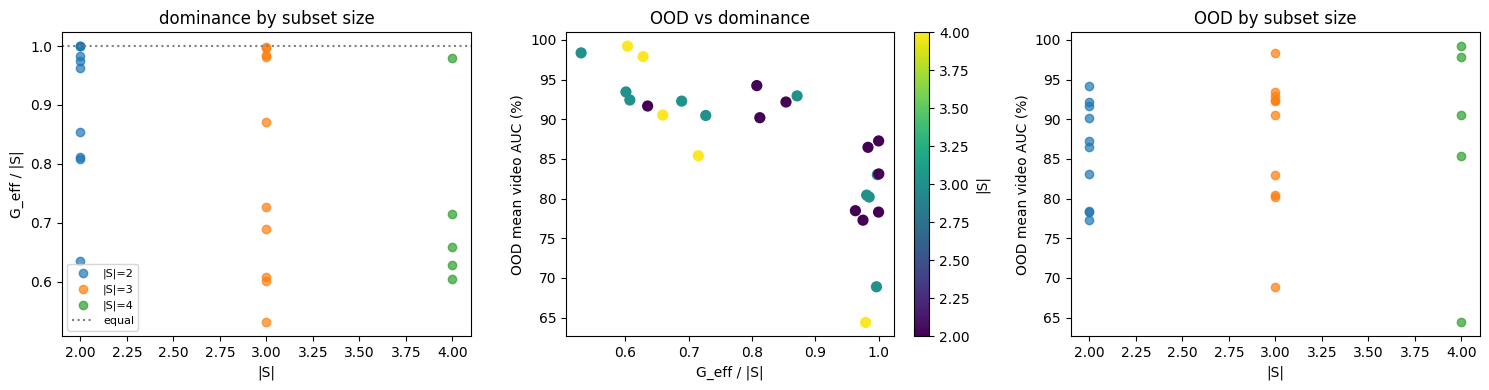

most dominated (lowest G_eff/|S|):


,subset,size,G_eff/|S|,OOD mean AUC,weights
13,F2F+NT+FSh,3,0.531,98.367,"{'F2F': 0.6615357513615902, 'NT': -0.088995479..."
11,F2F+FS+NT,3,0.601,93.441,"{'F2F': 0.6729694217049184, 'FS': 0.3185389984..."
4,F2F+FS+NT+FSh,4,0.604,99.214,"{'F2F': 0.46243968807527047, 'FS': 0.232589493..."
6,DF+F2F+NT,3,0.607,92.429,"{'DF': 0.45853535913638377, 'F2F': 0.580557717..."
2,DF+F2F+NT+FSh,4,0.628,97.898,"{'DF': 0.24238714098046055, 'F2F': 0.434225523..."


most balanced (highest G_eff/|S|):


,subset,size,G_eff/|S|,OOD mean AUC,weights
19,F2F+FS,2,1.000,83.112,"{'F2F': 0.49316178095058133, 'FS': 0.506838219..."
21,F2F+FSh,2,1.000,87.270,"{'F2F': 0.5104089420041289, 'FSh': 0.489591057..."
23,FS+FSh,2,0.999,78.304,"{'FS': 0.4882933889006597, 'FSh': 0.5117066110..."
7,DF+F2F+FSh,3,0.998,83.023,"{'DF': 0.3227149354036078, 'F2F': 0.3206302387..."
9,DF+FS+FSh,3,0.996,68.893,"{'DF': 0.30400954442239303, 'FS': 0.3470080650..."


Pearson correlation (G_eff/|S| vs OOD mean AUC): -0.768
means by size:


,G_eff/|S|,OOD mean AUC,explained
size,,,
2,0.903,85.920,0.738
3,0.799,87.251,0.729
4,0.717,87.490,0.696


In [8]:
# 5. Plots and tables
df = pd.DataFrame(rows)
df["tag"] = df["subset"]
display(df[["subset", "size", "G_eff", "G_eff/|S|", "explained", "seen AUC", "OOD mean AUC"]].round(3))
(M7_DIR / "geff_law.csv").write_text(
    df[["subset", "size", "G_eff", "G_eff/|S|", "explained", "seen AUC", "OOD mean AUC"]].to_csv(index=False))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for size, sub in df.groupby("size"):
    axes[0].scatter([size] * len(sub), sub["G_eff/|S|"], alpha=0.7, label=f"|S|={size}")
axes[0].axhline(1.0, color="gray", linestyle=":", label="equal")
axes[0].set_xlabel("|S|")
axes[0].set_ylabel("G_eff / |S|")
axes[0].set_title("dominance by subset size")
axes[0].legend(fontsize=8)

sc = axes[1].scatter(df["G_eff/|S|"], df["OOD mean AUC"], c=df["size"], cmap="viridis", s=50)
axes[1].set_xlabel("G_eff / |S|")
axes[1].set_ylabel("OOD mean video AUC (%)")
axes[1].set_title("OOD vs dominance")
plt.colorbar(sc, ax=axes[1], label="|S|")

for size, sub in df.groupby("size"):
    axes[2].scatter([size] * len(sub), sub["OOD mean AUC"], alpha=0.7)
axes[2].set_xlabel("|S|")
axes[2].set_ylabel("OOD mean video AUC (%)")
axes[2].set_title("OOD by subset size")
plt.tight_layout()
plt.show()

print("most dominated (lowest G_eff/|S|):")
display(df.nsmallest(5, "G_eff/|S|")[["subset", "size", "G_eff/|S|", "OOD mean AUC", "weights"]].round(3))
print("most balanced (highest G_eff/|S|):")
display(df.nlargest(5, "G_eff/|S|")[["subset", "size", "G_eff/|S|", "OOD mean AUC", "weights"]].round(3))

# correlation
corr = df["G_eff/|S|"].corr(df["OOD mean AUC"])
print(f"Pearson correlation (G_eff/|S| vs OOD mean AUC): {corr:.3f}")
by_size = df.groupby("size")[["G_eff/|S|", "OOD mean AUC", "explained"]].mean()
print("means by size:")
display(by_size.round(3))